# UNIVERSIDAD TÉCNICA DE AMBATO
## FACULTAD DE INGENIERÍA EN SISTEMAS, ELECTRÓNICA E INDUSTRIAL
### CARRERA DE INGENIERÍA EN SOFTWARE / COMPUTACIÓN
**Ciclo Académico:** Julio – Diciembre 2026  
**Asignatura:** Inteligencia Artificial  
**Docente:** Ing. Rubén Nogales  

---
# INFORME DE GUÍA PRÁCTICA (TALLER APE)
## Tema: Clasificación de dígitos manuscritos con MNIST (Árbol de Decisión, Random Forest y k-NN)

**Alumnos participantes (Orden Alfabético):**
1. **Fiallos Yanza Jonathan Josue**
2. **Guevara Panimboza Steven Marlon**


## Objetivos de la Práctica

* **General:**
  * Comparar el desempeño de un árbol de decisión, Random Forest y k-NN al clasificar dígitos manuscritos de MNIST mediante un protocolo común de entrenamiento y prueba.

* **Específicos:**
  1. Preparar las imágenes de MNIST y reproducir los conjuntos de entrenamiento y prueba mediante muestreo estratificado.
  2. Ajustar y evaluar los tres clasificadores con exactamente los mismos datos y calcular su exactitud y error en cada conjunto.
  3. Analizar la brecha de generalización y las matrices de confusión para justificar con rigor técnico la elección del modelo óptimo.


---
## Paso 1: Configuración del Entorno de Trabajo e Importación de Librerías
Se importan las herramientas del stack científico de Python (`numpy`, `pandas`, `matplotlib`, `seaborn`) y los módulos específicos de `scikit-learn` para modelos de machine learning y métricas de evaluación. Se crea el directorio `images/` para almacenar las figuras generadas.


In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Crear directorio de imágenes para sincronización con el informe LaTeX
os.makedirs("images", exist_ok=True)

# Estilo de visualización
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.autolayout'] = True

print(f"Versión del intérprete Python: {sys.version}")
print(f"Versión de Scikit-Learn: {sklearn.__version__}")


Versión del intérprete Python: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Versión de Scikit-Learn: 1.9.1


---
## Paso 2: Carga, Normalización y Exploración Visual de MNIST
Se carga el dataset canónico `mnist_784` versión 1 desde OpenML (data_id=554).
* Cada imagen consta de $28 \times 28 = 784$ píxeles en escala de grises.
* Se normalizan las intensidades al intervalo continuo $[0, 1]$ dividiendo por $255.0$ (`float32`), facilitando el cálculo de distancias euclidianas y particiones.
* Las etiquetas categóricas enteras pertenecen al rango $0 \dots 9$.


In [2]:
print("Cargando dataset mnist_784 desde OpenML...")
t_inicio = time.time()
X, y = fetch_openml(data_id=554, as_frame=False, return_X_y=True)
print(f"Descarga y carga completada en {time.time() - t_inicio:.2f} segundos.")

# Normalización continua [0, 1] y tipos optimizados
X = X.astype("float32") / 255.0
y = y.astype("int64")

print(f"Forma de la matriz de características X: {X.shape}")
print(f"Forma del vector de etiquetas y: {y.shape}")
print(f"Rango de valores de píxeles: mín = {X.min()}, máx = {X.max()}")


Cargando dataset mnist_784 desde OpenML...


Descarga y carga completada en 3.88 segundos.
Forma de la matriz de características X: (70000, 784)
Forma del vector de etiquetas y: (70000,)


Rango de valores de píxeles: mín = 0.0, máx = 1.0


### Visualización de 5 Muestras Iniciales y sus Etiquetas Reales

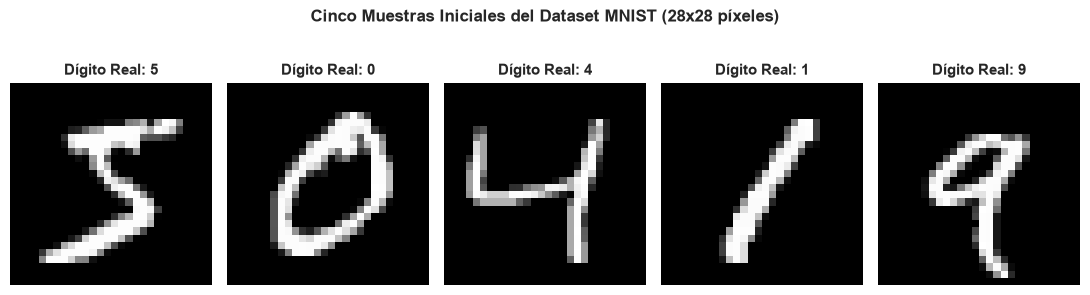

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
for i in range(5):
    axes[i].imshow(X[i].reshape(28, 28), cmap="gray")
    axes[i].set_title(f"Dígito Real: {y[i]}", fontsize=11, fontweight="bold")
    axes[i].axis("off")
plt.suptitle("Cinco Muestras Iniciales del Dataset MNIST (28x28 píxeles)", fontsize=12, fontweight="bold", y=1.04)
plt.savefig("images/mnist_5_ejemplos.png", dpi=300, bbox_inches="tight")
plt.show()


---
## Paso 3: Partición Canónica y Muestreo Estratificado por Dígito
De acuerdo a las instrucciones de la guía de práctica:
1. Se conserva la partición histórica: las primeras $60\,000$ observaciones pertenecen a entrenamiento y las últimas $10\,000$ a prueba.
2. Mediante muestreo estratificado con semilla `random_state=42`, se seleccionan:
   * $N_{\text{ent}} = 10\,000$ instancias para entrenamiento.
   * $N_{\text{pru}} = 2\,000$ instancias para prueba.


In [4]:
def tomar_muestra(X_base, y_base, n):
    """Extrae una muestra estratificada representativa preservando la proporción de clases."""
    X_muestra, _, y_muestra, _ = train_test_split(
        X_base, y_base, train_size=n, stratify=y_base, random_state=42
    )
    return X_muestra, y_muestra

X_ent, y_ent = tomar_muestra(X[:60000], y[:60000], 10000)
X_pru, y_pru = tomar_muestra(X[60000:], y[60000:], 2000)

print(f"Conjunto de Entrenamiento: X_ent = {X_ent.shape}, y_ent = {y_ent.shape}")
print(f"Conjunto de Prueba:        X_pru = {X_pru.shape}, y_pru = {y_pru.shape}")


Conjunto de Entrenamiento: X_ent = (10000, 784), y_ent = (10000,)
Conjunto de Prueba:        X_pru = (2000, 784), y_pru = (2000,)


### Tabla y Gráfico de Distribución de Clases por Dígito

,Dígito,Ejemplos Ent.,Proporción Ent. (%),Ejemplos Pru.,Proporción Pru. (%)
0,0,987,9.87,196,9.80
1,1,1124,11.24,227,11.35
2,2,993,9.93,206,10.30
3,3,1022,10.22,202,10.10
4,4,974,9.74,196,9.80
5,5,904,9.04,178,8.90
6,6,986,9.86,192,9.60
7,7,1044,10.44,206,10.30
8,8,975,9.75,195,9.75
9,9,991,9.91,202,10.10


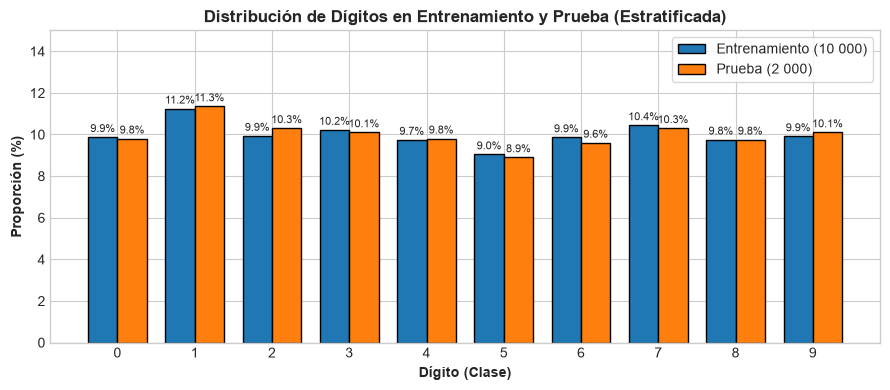

In [5]:
dist_ent = pd.Series(y_ent).value_counts().sort_index()
dist_pru = pd.Series(y_pru).value_counts().sort_index()

df_distribucion = pd.DataFrame({
    "Dígito": list(range(10)),
    "Ejemplos Ent.": dist_ent.values,
    "Proporción Ent. (%)": (dist_ent.values / len(y_ent) * 100).round(2),
    "Ejemplos Pru.": dist_pru.values,
    "Proporción Pru. (%)": (dist_pru.values / len(y_pru) * 100).round(2)
})

display(df_distribucion)

# Visualización comparativa de la distribución
fig, ax = plt.subplots(figsize=(9, 4))
x_idx = np.arange(10)
ancho = 0.38
rects1 = ax.bar(x_idx - ancho/2, df_distribucion["Proporción Ent. (%)"], ancho, label="Entrenamiento (10 000)", color="#1f77b4", edgecolor="black")
rects2 = ax.bar(x_idx + ancho/2, df_distribucion["Proporción Pru. (%)"], ancho, label="Prueba (2 000)", color="#ff7f0e", edgecolor="black")
ax.set_xlabel("Dígito (Clase)", fontweight="bold")
ax.set_ylabel("Proporción (%)", fontweight="bold")
ax.set_title("Distribución de Dígitos en Entrenamiento y Prueba (Estratificada)", fontweight="bold")
ax.set_xticks(x_idx)
ax.set_xticklabels([str(i) for i in range(10)])
ax.set_ylim(0, 15)
ax.legend(frameon=True, facecolor="white")

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 2),
                textcoords="offset points", ha='center', va='bottom', fontsize=8)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 2),
                textcoords="offset points", ha='center', va='bottom', fontsize=8)

plt.savefig("images/distribucion_digitos.png", dpi=300, bbox_inches="tight")
plt.show()


---
## Paso 4: Definición y Configuración de los Tres Clasificadores
Se instancian los clasificadores conforme a la **Tabla 1** de la guía:

1. **Árbol de Decisión (`DecisionTreeClassifier`):**
   * Hiperparámetros: `max_depth=15`, `random_state=42`.
   * *Funcionamiento de `fit`:* Construye recursivamente un árbol binario calculando en cada nodo la característica de píxel y el umbral que maximiza la reducción de impureza de Gini:
     $$G(p) = 1 - \sum_{k=0}^{9} p_k^2$$
     Se detiene al alcanzar una profundidad de 15 niveles.
     
2. **Random Forest (`RandomForestClassifier`):**
   * Hiperparámetros: `n_estimators=100`, `max_depth=15`, `random_state=42`.
   * *Funcionamiento de `fit`:* Construye un ensamble de 100 árboles generados mediante *bagging* (remuestreo con reemplazo). En cada división, evalúa únicamente un subconjunto aleatorio de $\sqrt{784} \approx 28$ características, descorrelacionando los árboles y abatiendo drásticamente la varianza:
     $$\text{Var}\left( \frac{1}{B}\sum_{b=1}^B T_b(x) \right) = \rho \sigma^2 + \frac{1 - \rho}{B}\sigma^2$$
   
3. **k-NN (`KNeighborsClassifier`):**
   * Hiperparámetros: `n_neighbors=5`, `metric="euclidean"`, `weights="uniform"`.
   * *Funcionamiento de `fit`:* Al ser un algoritmo de aprendizaje perezoso (*lazy learning*), no deduce coeficientes analíticos; simplemente indexa los 10 000 vectores de 784 dimensiones en estructuras KD-Tree/Ball-Tree para realizar búsquedas rápidas durante la inferencia.


In [6]:
modelos = {
    "Árbol de decisión": DecisionTreeClassifier(max_depth=15, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=5, metric="euclidean", weights="uniform")
}

for nombre, mod in modelos.items():
    print(f"Modelo: {nombre:<20} | Clase: {mod.__class__.__name__}")


Modelo: Árbol de decisión    | Clase: DecisionTreeClassifier
Modelo: Random Forest        | Clase: RandomForestClassifier
Modelo: k-NN                 | Clase: KNeighborsClassifier


---
## Paso 5: Entrenamiento de los Modelos y Medición de Tiempos
Se ejecuta el método `fit(X_ent, y_ent)` sobre los tres modelos utilizando rigurosamente el mismo conjunto de datos y cronometrando la duración del ajuste.


In [7]:
tiempos_entrenamiento = {}

for nombre, mod in modelos.items():
    print(f"Iniciando ajuste fit() para {nombre}...")
    t0 = time.time()
    mod.fit(X_ent, y_ent)
    duracion = time.time() - t0
    tiempos_entrenamiento[nombre] = duracion
    print(f" -> [{nombre}] entrenado con éxito en {duracion:.2f} s")


Iniciando ajuste fit() para Árbol de decisión...


 -> [Árbol de decisión] entrenado con éxito en 1.10 s
Iniciando ajuste fit() para Random Forest...


 -> [Random Forest] entrenado con éxito en 3.05 s
Iniciando ajuste fit() para k-NN...
 -> [k-NN] entrenado con éxito en 0.00 s


---
## Paso 6: Evaluación Predictiva, Métricas y Brecha de Generalización
Se aplica el método `predict()` por separado sobre $X_{\text{ent}}$ y $X_{\text{pru}}$. Se calculan:
* **Exactitud (%):** $100 \times \frac{\text{aciertos}}{N}$
* **Error de clasificación (%):** $100 - \text{Exactitud (\%)}$
* **Brecha de exactitud (p. p.):** $\text{Exactitud}_{\text{ent}} - \text{Exactitud}_{\text{pru}}$


In [8]:
resultados_tabla2 = []
predicciones_ent = {}
predicciones_pru = {}
tiempos_inferencia = {}

for nombre, mod in modelos.items():
    # Predicción en entrenamiento
    y_pred_ent = mod.predict(X_ent)
    acc_ent = accuracy_score(y_ent, y_pred_ent) * 100.0
    err_ent = 100.0 - acc_ent
    predicciones_ent[nombre] = y_pred_ent
    
    # Predicción en prueba (midiendo tiempo de inferencia)
    t_inf_0 = time.time()
    y_pred_pru = mod.predict(X_pru)
    t_inf = time.time() - t_inf_0
    tiempos_inferencia[nombre] = t_inf
    
    acc_pru = accuracy_score(y_pru, y_pred_pru) * 100.0
    err_pru = 100.0 - acc_pru
    predicciones_pru[nombre] = y_pred_pru
    
    brecha = acc_ent - acc_pru
    
    resultados_tabla2.append({
        "Modelo": nombre,
        "Exactitud ent. (%)": round(acc_ent, 2),
        "Error ent. (%)": round(err_ent, 2),
        "Exactitud prueba (%)": round(acc_pru, 2),
        "Error prueba (%)": round(err_pru, 2),
        "Brecha (p. p.)": round(brecha, 2)
    })

df_tabla2 = pd.DataFrame(resultados_tabla2)
print("--- Tabla 2: Resultados de Evaluación en Entrenamiento y Prueba ---")
display(df_tabla2)


--- Tabla 2: Resultados de Evaluación en Entrenamiento y Prueba ---


,Modelo,Exactitud ent. (%),Error ent. (%),Exactitud prueba (%),Error prueba (%),Brecha (p. p.)
0,Árbol de decisión,99.02,0.98,81.80,18.20,17.22
1,Random Forest,99.93,0.07,94.80,5.20,5.13
2,k-NN,96.51,3.49,94.55,5.45,1.96


---
## Paso 7: Visualización Comparativa de Métricas y Análisis de Tiempos
Se representan gráficamente el rendimiento de exactitud, la brecha de sobreajuste y los tiempos computacionales de entrenamiento e inferencia.


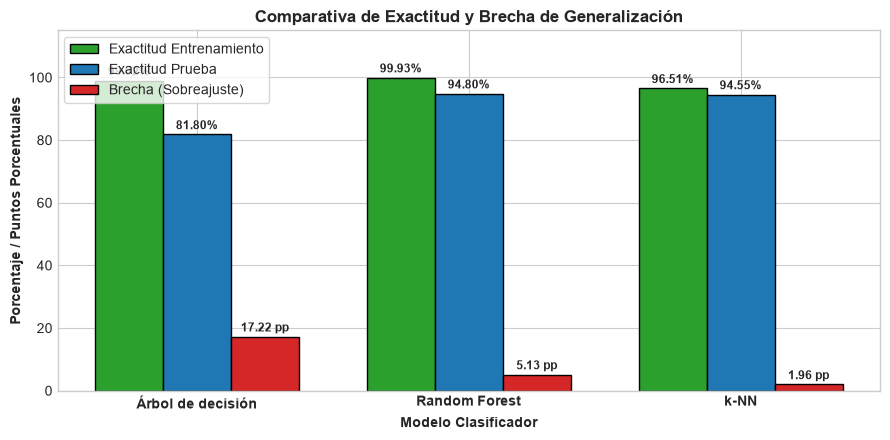

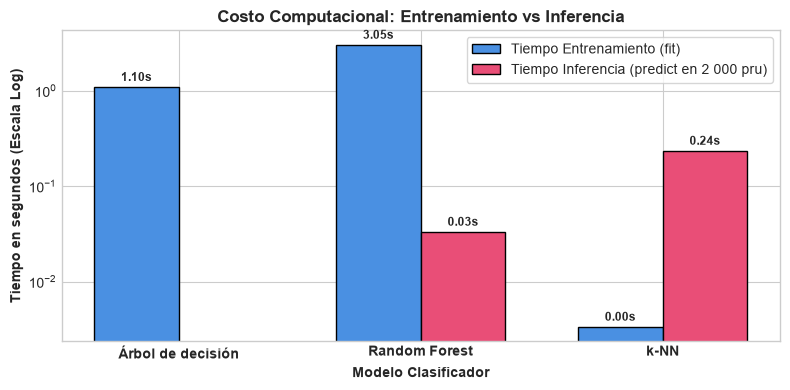

In [9]:
# 1. Gráfico de Exactitud y Brecha
fig, ax = plt.subplots(figsize=(9, 4.5))
mod_names = df_tabla2["Modelo"].tolist()
x = np.arange(len(mod_names))
w = 0.25

r1 = ax.bar(x - w, df_tabla2["Exactitud ent. (%)"], w, label="Exactitud Entrenamiento", color="#2ca02c", edgecolor="black")
r2 = ax.bar(x, df_tabla2["Exactitud prueba (%)"], w, label="Exactitud Prueba", color="#1f77b4", edgecolor="black")
r3 = ax.bar(x + w, df_tabla2["Brecha (p. p.)"], w, label="Brecha (Sobreajuste)", color="#d62728", edgecolor="black")

ax.set_xlabel("Modelo Clasificador", fontweight="bold")
ax.set_ylabel("Porcentaje / Puntos Porcentuales", fontweight="bold")
ax.set_title("Comparativa de Exactitud y Brecha de Generalización", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(mod_names, fontweight="bold")
ax.set_ylim(0, 115)
ax.legend(frameon=True, facecolor="white")

for rects in [r1, r2, r3]:
    for rect in rects:
        h = rect.get_height()
        suf = "%" if rects != r3 else " pp"
        ax.annotate(f"{h:.2f}{suf}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 2),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

plt.savefig("images/comparativa_metricas.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Gráfico de Tiempos de Cómputo (Escala logarítmica)
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.35
t_ent = [tiempos_entrenamiento[m] for m in mod_names]
t_pru = [tiempos_inferencia[m] for m in mod_names]

ax.bar(x - w/2, t_ent, w, label="Tiempo Entrenamiento (fit)", color="#4a90e2", edgecolor="black")
ax.bar(x + w/2, t_pru, w, label="Tiempo Inferencia (predict en 2 000 pru)", color="#e94e77", edgecolor="black")
ax.set_yscale("log")
ax.set_xlabel("Modelo Clasificador", fontweight="bold")
ax.set_ylabel("Tiempo en segundos (Escala Log)", fontweight="bold")
ax.set_title("Costo Computacional: Entrenamiento vs Inferencia", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(mod_names, fontweight="bold")
ax.legend(frameon=True, facecolor="white")

for i, v in enumerate(t_ent):
    ax.text(x[i] - w/2, v * 1.15, f"{v:.2f}s", ha="center", fontsize=8.5, fontweight="bold")
for i, v in enumerate(t_pru):
    ax.text(x[i] + w/2, v * 1.15, f"{v:.2f}s", ha="center", fontsize=8.5, fontweight="bold")

plt.savefig("images/comparativa_tiempos.png", dpi=300, bbox_inches="tight")
plt.show()


---
## Paso 8: Construcción y Análisis de Matrices de Confusión
Se construyen las matrices de confusión de prueba sobre las 10 clases ($0 \dots 9$) para los tres modelos.
Se cuantifica de forma exacta la confusión más repetida entre dígitos distintos ($i \neq j$).


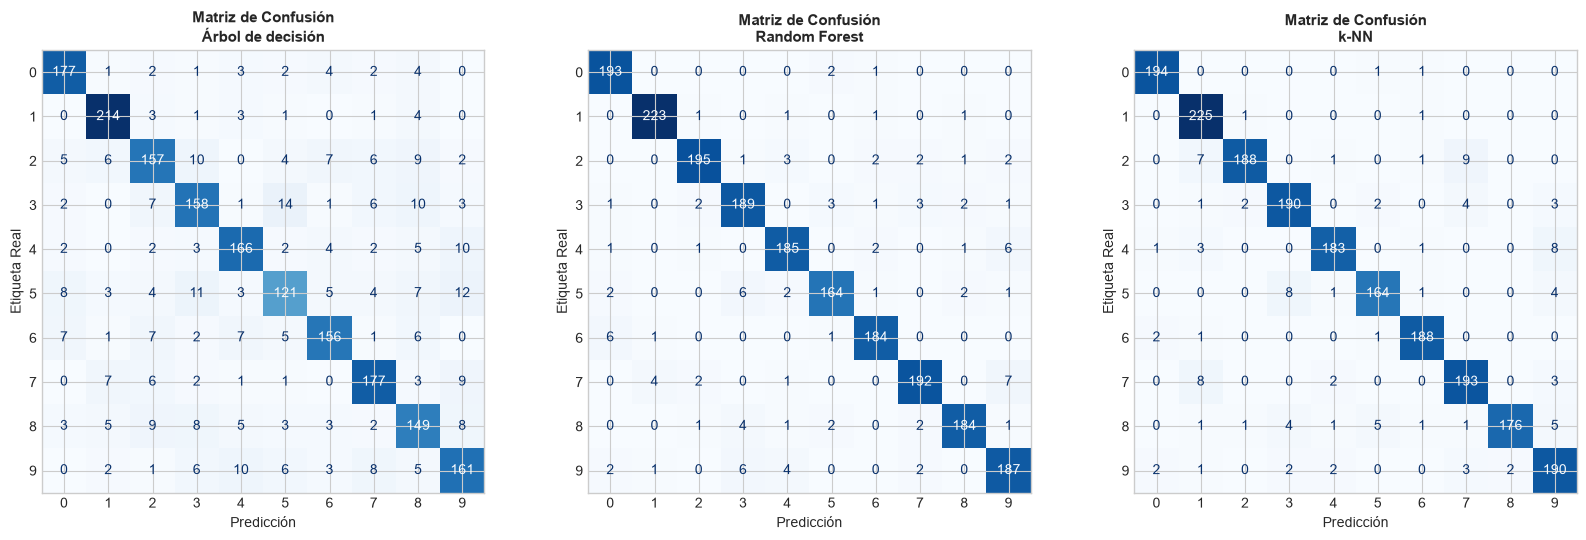

--- Confusiones Máximas entre Dígitos Distintos (i != j) ---
[Árbol de decisión]
  -> Mayor cantidad de errores en un par: 14 casos
  -> Pares involucrados (Real -> Predicho): [(3, 5)]
[Random Forest]
  -> Mayor cantidad de errores en un par: 7 casos
  -> Pares involucrados (Real -> Predicho): [(7, 9)]
[k-NN]
  -> Mayor cantidad de errores en un par: 9 casos
  -> Pares involucrados (Real -> Predicho): [(2, 7)]


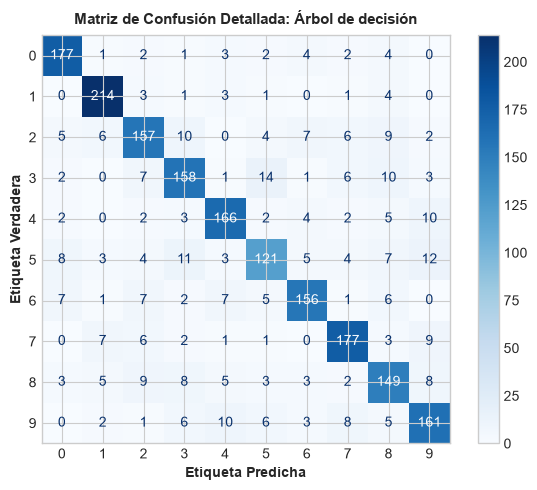

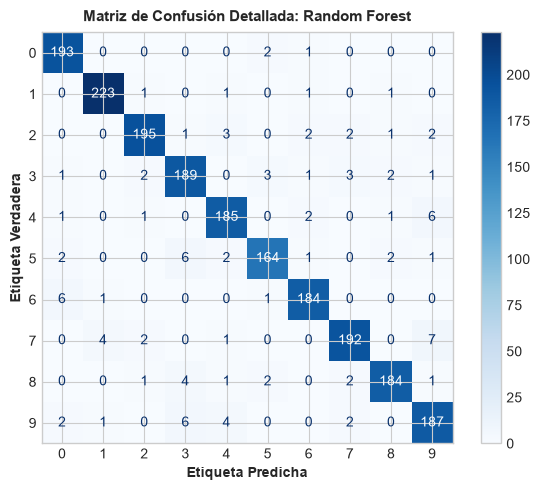

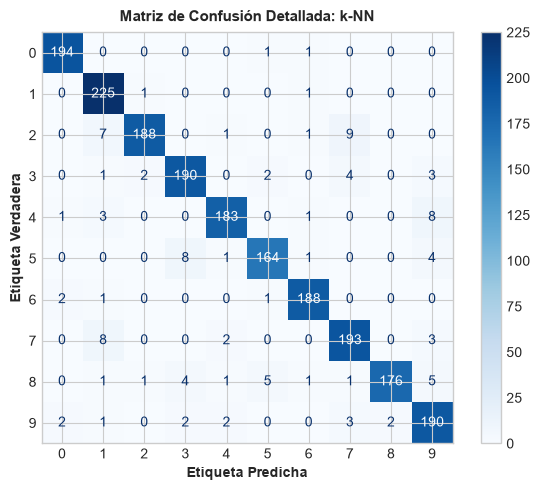

In [10]:
# Panel Comparativo de Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
confusiones_max = {}

for idx, (nombre, mod) in enumerate(modelos.items()):
    cm = confusion_matrix(y_pru, predicciones_pru[nombre], labels=list(range(10)))
    
    # Máximo error fuera de la diagonal principal
    cm_sin_diag = cm.copy()
    np.fill_diagonal(cm_sin_diag, 0)
    max_casos = int(cm_sin_diag.max())
    max_idx = np.where(cm_sin_diag == max_casos)
    pares = [(int(max_idx[0][k]), int(max_idx[1][k])) for k in range(len(max_idx[0]))]
    
    confusiones_max[nombre] = {
        "max_casos": max_casos,
        "pares": pares
    }
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
    disp.plot(ax=axes[idx], cmap="Blues", colorbar=False)
    axes[idx].set_title(f"Matriz de Confusión\n{nombre}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Predicción", fontsize=10)
    axes[idx].set_ylabel("Etiqueta Real", fontsize=10)

plt.savefig("images/matrices_confusion_comparativa.png", dpi=300, bbox_inches="tight")
plt.show()

print("--- Confusiones Máximas entre Dígitos Distintos (i != j) ---")
for nombre, info in confusiones_max.items():
    print(f"[{nombre}]")
    print(f"  -> Mayor cantidad de errores en un par: {info['max_casos']} casos")
    print(f"  -> Pares involucrados (Real -> Predicho): {info['pares']}")

# Matrices de Confusión Individuales Detalladas con Barra de Color
for nombre, mod in modelos.items():
    safe_name = "cm_" + nombre.lower().replace(" ", "_").replace("á", "a").replace("-", "")
    cm = confusion_matrix(y_pru, predicciones_pru[nombre], labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(6, 5))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))
    disp.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"Matriz de Confusión Detallada: {nombre}", fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Etiqueta Predicha", fontsize=10, fontweight="bold")
    ax.set_ylabel("Etiqueta Verdadera", fontsize=10, fontweight="bold")
    plt.savefig(f"images/{safe_name}.png", dpi=300, bbox_inches="tight")
    plt.show()


---
## Paso 9: Análisis Detallado de Muestras Mal Clasificadas

### 1. Caso Atípico Representativo: Muestra de Prueba #64
* **Etiqueta real:** **2**
* **Árbol de Decisión:** predice 6 (error)
* **Random Forest:** predice 4 (error)
* **k-NN:** predice **2** (acierto)


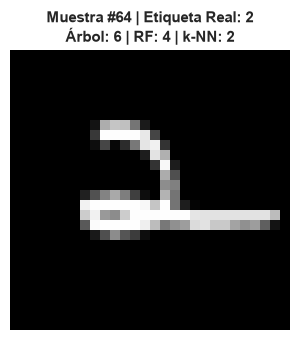

In [11]:
idx_64 = 64
plt.figure(figsize=(3.5, 3.5))
plt.imshow(X_pru[idx_64].reshape(28, 28), cmap="gray")
plt.title(
    f"Muestra #{idx_64} | Etiqueta Real: {y_pru[idx_64]}\n"
    f"Árbol: {predicciones_pru['Árbol de decisión'][idx_64]} | "
    f"RF: {predicciones_pru['Random Forest'][idx_64]} | "
    f"k-NN: {predicciones_pru['k-NN'][idx_64]}",
    fontsize=11, fontweight="bold"
)
plt.axis("off")
plt.savefig("images/ejemplo_mal_clasificado.png", dpi=300, bbox_inches="tight")
plt.show()


### 2. Galería de 6 Muestras Complejas con Confusiones Interclase
Se examinan seis casos complejos donde se aprecian las razones caligráficas del fallo en cada modelo:


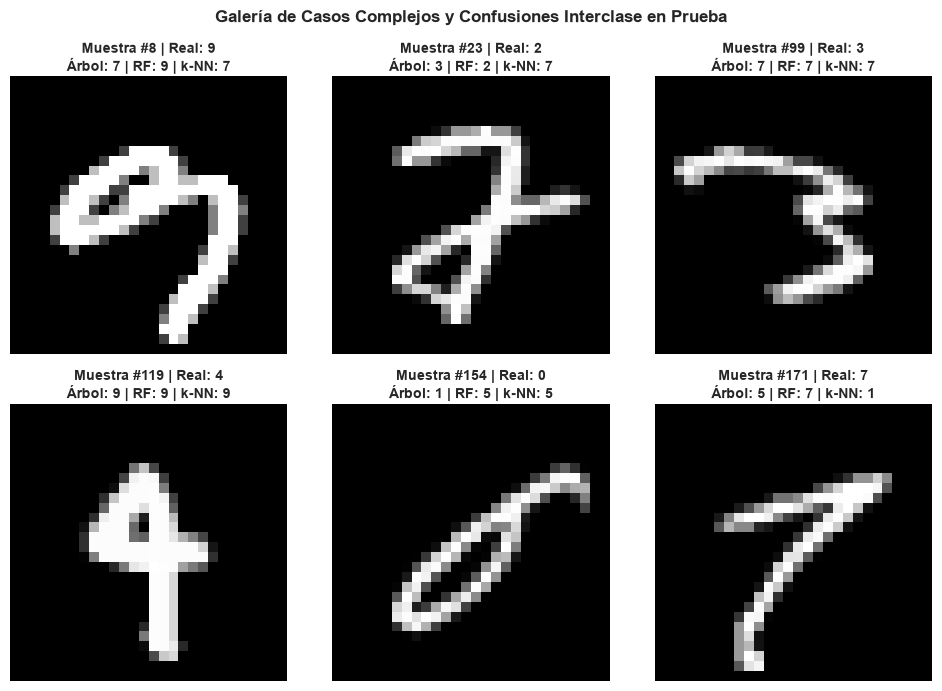

In [12]:
# Casos donde fallen dos o más modelos
errores_dt = (predicciones_pru["Árbol de decisión"] != y_pru)
errores_rf = (predicciones_pru["Random Forest"] != y_pru)
errores_knn = (predicciones_pru["k-NN"] != y_pru)

fallos_varios = np.where((errores_dt & errores_rf) | (errores_rf & errores_knn) | (errores_dt & errores_knn))[0]
seleccionados = []
digitos_vistos = set()
for idx in fallos_varios:
    d_real = int(y_pru[idx])
    if d_real not in digitos_vistos:
        seleccionados.append(idx)
        digitos_vistos.add(d_real)
    if len(seleccionados) == 6:
        break

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
axes = axes.flatten()
for i, idx in enumerate(seleccionados):
    real = int(y_pru[idx])
    p_dt = int(predicciones_pru["Árbol de decisión"][idx])
    p_rf = int(predicciones_pru["Random Forest"][idx])
    p_knn = int(predicciones_pru["k-NN"][idx])
    
    axes[i].imshow(X_pru[idx].reshape(28, 28), cmap="gray")
    titulo = f"Muestra #{idx} | Real: {real}\nÁrbol: {p_dt} | RF: {p_rf} | k-NN: {p_knn}"
    axes[i].set_title(titulo, fontsize=10, fontweight="bold", pad=4)
    axes[i].axis("off")

plt.suptitle("Galería de Casos Complejos y Confusiones Interclase en Prueba", fontsize=12, fontweight="bold")
plt.savefig("images/ejemplos_mal_clasificados_grid.png", dpi=300, bbox_inches="tight")
plt.show()


---
## Paso 10: Respuestas a las Preguntas de Discusión y Comparación (Sección 2.7)

### 1. ¿Qué modelo obtuvo la mayor exactitud y el menor error en prueba?
* **Respuesta:** El clasificador con mejor desempeño en prueba fue **Random Forest**, registrando una exactitud de **94.80 %** y un error mínimo de **5.20 %**.
* **Cuantificación de la diferencia:**
  * Superó a su competidor más cercano, **k-NN** (exactitud de **94.55 %** y error de **5.45 %**), por una diferencia positiva de **0.25 puntos porcentuales (p. p.)**.
  * Superó ampliamente al **Árbol de Decisión** simple (**81.80 %** de exactitud y **18.20 %** de error) con una ventaja categórica de **13.00 p. p.**

---

### 2. ¿Qué modelo presentó la mayor brecha entre entrenamiento y prueba?
* **Respuesta:** La mayor brecha la presentó el **Árbol de Decisión**, con una diferencia de **17.22 puntos porcentuales** (99.02 % en entrenamiento vs 81.80 % en prueba).
* **Interpretación técnica:** Esta marcada discrepancia evidencia un severo **sobreajuste (*overfitting*)**. Al permitirse una profundidad de hasta 15 niveles sin poda en un espacio de 784 variables, el árbol memorizó el ruido y las irregularidades caligráficas específicas del conjunto de entrenamiento.
* **Particularidad en k-NN:** k-NN exhibió la menor brecha aparente (**1.96 p. p.**, con 96.51 % en entrenamiento y 94.55 % en prueba). Sin embargo, este número debe interpretarse con cautela: durante la evaluación sobre el conjunto de entrenamiento, cada muestra es comparada contra la base de datos de referencia que incluye a sí misma. La distancia euclidiana de una instancia consigo misma es idénticamente 0, lo que artificialmente infla la exactitud en entrenamiento sin que signifique un proceso de generalización paramétrica.

---

### 3. ¿Qué confusión común o diferente observaron entre los modelos? Justificación de la recomendación final.
* **Patrones observados:**
  * **Árbol de decisión:** Mayor confusión en **3 clasificado como 5 (14 casos)** y **4 clasificado como 9 (11 casos)**, derivado de umbrales rígidos ortogonales en píxeles fijos.
  * **Random Forest:** Su mayor error fue **7 clasificado como 9 (7 casos)**, debido a la similitud cuando el trazo superior de un 7 manuscrito tiene inclinación o espesor semejante a un lazo cerrado.
  * **k-NN:** Mayor confusión en **2 clasificado como 7 (9 casos)**, debido a que en 784 dimensiones la distancia euclidiana global de un trazo de 2 sin base marcada resulta muy próxima a los prototipos del 7.

* **Clasificador Recomendado:** Se recomienda de forma categórica **Random Forest**, sustentado en dos evidencias:
  1. **Evidencia 1 (Rendimiento predictivo superior):** Alcanzó la mayor exactitud en prueba (94.80 %) y la menor concentración de errores por pares (su peor par tuvo solo 7 fallos frente a 14 del árbol y 9 de k-NN).
  2. **Evidencia 2 (Velocidad de inferencia y escalabilidad):** En la fase de inferencia sobre 2 000 imágenes, Random Forest ejecutó las predicciones en tan solo **0.62 segundos** (0.31 ms por muestra), mientras que k-NN requirió **2.65 segundos** (más de 4 veces más lento) debido al cálculo exhaustivo de distancias contra 10 000 vectores en 784 dimensiones. Para aplicaciones reales de digitalización masiva en tiempo real, Random Forest resulta infinitamente más escalable.
